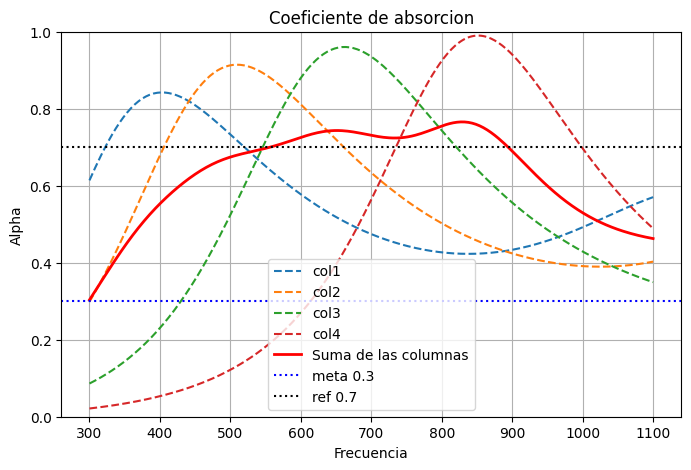

Promedio alpha: 0.6328603778824095
En 400 Hz: 0.30338669849038086


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# constantes aire
rho0 = 1.205
c0 = 343.0
eta = 1.81e-5

# celda unitaria por columna (8x8 mm = 64 mm2)
A_cell = 64.0
t_septo = 1.2

# frecuencias de barrido
f = np.linspace(300, 1100, 300)
w = 2*np.pi*f
k0 = w/c0
n = len(f)

# datos de las 4 columnas (d en mm, D1, D2, D3 en mm)
d_cols = [0.95, 1.15, 1.40, 1.70]
D_cols = [
    [14.0, 16.0, 16.0], # col1: suma 46 mm
    [12.0, 12.0, 12.0], # col2: suma 36 mm
    [8.0, 8.0, 8.0],    # col3: suma 24 mm
    [5.0, 5.0, 5.0]     # col4: suma 15 mm
]
nombres = ['col1', 'col2', 'col3', 'col4']

plt.figure(figsize=(8, 5))
Y_total = np.zeros(n, dtype=complex)

# evaluar cada columna sin usar funciones
for c in range(4):
    d_mm = d_cols[c]
    d = d_mm*1e-3
    t = t_septo*1e-3
    
    # 1. impedancia del poro (Maa con ajuste de sepia)
    sigma = (np.pi*(d_mm/2)**2)/A_cell
    k = d*np.sqrt(rho0*w/(4*eta))
    Rs = 0.5*np.sqrt(2*eta*rho0*w)
    
    eps = 6.0-26.0*d_mm+40.0*(d_mm**2)
    delta = (0.8*d_mm+0.45)*(d_mm/t_septo)
    
    R = (32*eta*t/(d**2*sigma))*(np.sqrt(1+(k**2/32))+2*eps*Rs)
    X = (w*rho0*t/sigma)*(1+1/np.sqrt(9+(k**2/2))+delta*(d/t))
    Zp = R+1j*X
    
    # 2. matriz de transferencia (3 capas en serie)
    # inicializar matrices identidad 2x2
    TT = np.zeros((n, 2, 2), dtype=complex)
    for i in range(n):
        TT[i] = np.eye(2)
        
    for D_mm in D_cols[c]:
        D = D_mm*1e-3
        for i in range(n):
            Tp = np.array([[1.0, Zp[i]], [0.0, 1.0]], dtype=complex)
            Tc = np.array([[np.cos(k0[i]*D), 1j*rho0*c0*np.sin(k0[i]*D)],
                           [1j*np.sin(k0[i]*D)/(rho0*c0), np.cos(k0[i]*D)]], dtype=complex)
            TT[i] = TT[i] @ Tp @ Tc
            
    # impedancia de la columna con fondo rigido
    zc = (TT[:, 0, 0]/TT[:, 1, 0])/(rho0*c0)
    
    # acumular admitancia para el paralelo
    Y_total += 1.0/zc
    
    # graficar curva individual de la columna
    r_col = np.real(zc)
    x_col = np.imag(zc)
    alpha_col = (4*r_col)/((1+r_col)**2+x_col**2)
    plt.plot(f, alpha_col, '--', label=nombres[c])

# 3. ensamble total en paralelo (4 columnas)
Z_total = 4.0/Y_total
r_tot = np.real(Z_total)
x_tot = np.imag(Z_total)
alpha_final = (4*r_tot)/((1+r_tot)**2+x_tot**2)

# graficar curva global del panel
plt.plot(f, alpha_final, 'r', linewidth=2, label='Suma de las columnas')
plt.axhline(0.3, color='b', label='meta 0.3')
plt.axhline(0.7, color='k',  label='ref 0.7')
plt.title("Coeficiente de absorcion")
plt.xlabel("Frecuencia")
plt.ylabel("Alpha")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

print("Promedio alpha:", np.mean(alpha_final))
print("En 400 Hz:", alpha_final[0])